# 10 FastText文本分类、迁移学习与Transformers Pipeline入门

本篇对应 `03-视频/day10`，已核对当天 **17个视频文件名**，并在线阅读 `01-课件/09-迁移学习-上.pdf` 全44页，以及 `10-迁移学习-中.pdf` 第1—39页；额外查看第40—41页以确认下一部分进入Auto模型。day10的主线已经从手写Transformer转到 **FastText分类与调优 → 词向量迁移 → 预训练模型 → Pipeline入门**。

02讲过FastText词向量，本篇重点是有标签的 `train_supervised` 文本分类。三个Pipeline任务是文本分类、特征提取和遮蔽填空；课件后续的抽取式问答、摘要、NER与AutoModel不在本篇详细展开。

延续全Markdown Notebook：代码按顺序复制到同一个Python会话执行，输出已附在代码后面。课程视频未逐节转录，课程原代码和cooking原数据未读取；本篇使用独立教学语料。所有图片均嵌入本Notebook的attachments，不依赖单独图片文件。

**实测边界**：FastText使用人工小语料真实训练、预测、评估和保存加载；Transformers使用随机初始化的本地小BERT验证Pipeline接口，没有预训练语义能力。自动调参、中文公开预训练模型和大型词向量下载示例分别标注“未执行”。

## 1. 先分清本篇的四类模型与接口

| 场景 | 核心接口 | 训练或输入 | 典型输出 |
| --- | --- | --- | --- |
| FastText无监督词向量（回顾02） | `train_unsupervised` | 无标签文本，CBOW/SkipGram | 一个词的向量、近邻 |
| FastText监督分类（本篇重点） | `train_supervised` | `__label__标签` + 文本 | 标签和分数 |
| 预训练编码器 | `BertModel` / 特征提取Pipeline | tokenizer得到的ID与mask | 每个token的上下文表示 |
| 带任务头的Transformer | 分类头、MLM头等 | 文本与匹配的模型/tokenizer | 类别概率、填空候选 |

FastText通过浅层结构、词/词组特征和输出层完成高效分类。它适合建立快速基线，不是完整的NER、机器翻译或通用聊天框架。Transformer提供更复杂的上下文建模，但模型选择、计算成本和任务训练也更重要。

本篇学习目标：能准备FastText数据；能解释HS与负采样；能看懂P@k/R@k；能调整epoch、lr、wordNgrams和loss；能保存复用模型；能区分“直接使用”与“微调”；能选择三种Pipeline对应的任务头。

## 2. 环境与示例约定

课件给出旧Linux/Python3.8与Transformers4.19环境。学习本篇无需克隆整个Transformers源码，也无需系统级sudo安装。建议建立独立虚拟环境，并记录版本。本篇实测依赖为Python3.12、FastText0.9.2、NumPy1.26.4和Transformers4.57.6；PyTorch版本见下方实测输出。

Windows可安装提供预编译包的 `fasttext-wheel==0.9.2`，导入名仍是 `fasttext`。它是社区wheel发行包；官方包名是 `fasttext`，环境能编译时也可使用官方包。不要在同一个环境同时安装两种发行包。旧FastText的Python包装与NumPy2的 `copy=False` 行为存在兼容问题，本篇使用NumPy1.26.4，不修改用户现有环境。

```text
# 在独立环境中按需安装；此为安装命令，不是Python代码
pip install numpy==1.26.4 fasttext-wheel==0.9.2 transformers==4.57.6 torch matplotlib
```

```python
import re, math, random, platform, importlib.metadata
from pathlib import Path
import numpy as np
import torch, fasttext, transformers
import matplotlib.pyplot as plt

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
plt.rcParams['font.family'] = 'Microsoft YaHei'
plt.rcParams['axes.unicode_minus'] = False
WORK = Path('nlp_day10_demo')
WORK.mkdir(exist_ok=True)
print('Python:', platform.python_version())
print('NumPy:', np.__version__, '| PyTorch:', torch.__version__)
print('FastText wheel:', importlib.metadata.version('fasttext-wheel'))
print('Transformers:', transformers.__version__)
print('示例文件夹:', WORK)
```

本段实测输出：

```text
Python: 3.12.13
NumPy: 1.26.4 | PyTorch: 2.14.1+cpu
FastText wheel: 0.9.2
Transformers: 4.57.6
示例文件夹: nlp_day10_demo
```

示例代码会在当前目录生成教学数据和模型文件。这些文件不是本笔记的图片依赖；Notebook内嵌的图可以直接阅读。固定种子和单线程有助于复现，跨平台数值仍可能略有不同。

## 3. FastText分类：平均特征，再预测标签

设文本分词后得到 `w₁,…,wₙ`，并加入word n-gram特征，形成特征集合 `F(x)`。一个简化表达是：

$$h(x)=\frac{1}{|F(x)|}\sum_{f\in F(x)}v_f,\qquad z=Wh(x)$$
$$p(y=j\mid x)=\frac{\exp(z_j)}{\sum_{c=1}^{C}\exp(z_c)},\qquad \mathcal L=-\log p(y_{true}\mid x)$$

输入向量和输出标签权重一起学习。上式强调“特征平均 + 线性输出”，具体实现还有哈希桶、子词与损失设置。它与CBOW的浅层平均结构相似，但CBOW预测词，监督FastText预测标签，训练目标不同。

| 特征 | 参数 | 例子 | 学到什么 |
| --- | --- | --- | --- |
| 单词 | 基本输入 | `not`, `good` | 词本身的信息 |
| 连续词组 | `wordNgrams=2` | `not good` | 相邻词组合，补充局部顺序 |
| 单词内字符子词 | `minn/maxn` | 单词内部字符片段 | 拼写/形态与未登录词表示 |
| 哈希特征桶 | `bucket` | 把n-gram映射到桶 | 控制空间，可能出现碰撞 |

**word n-gram不是字符n-gram**。监督分类默认 `wordNgrams=1`，字符子词默认关闭（`minn=maxn=0`）；词向量训练通常启用字符子词。FastText的局部词组不能替代Transformer对长距离语境的建模。

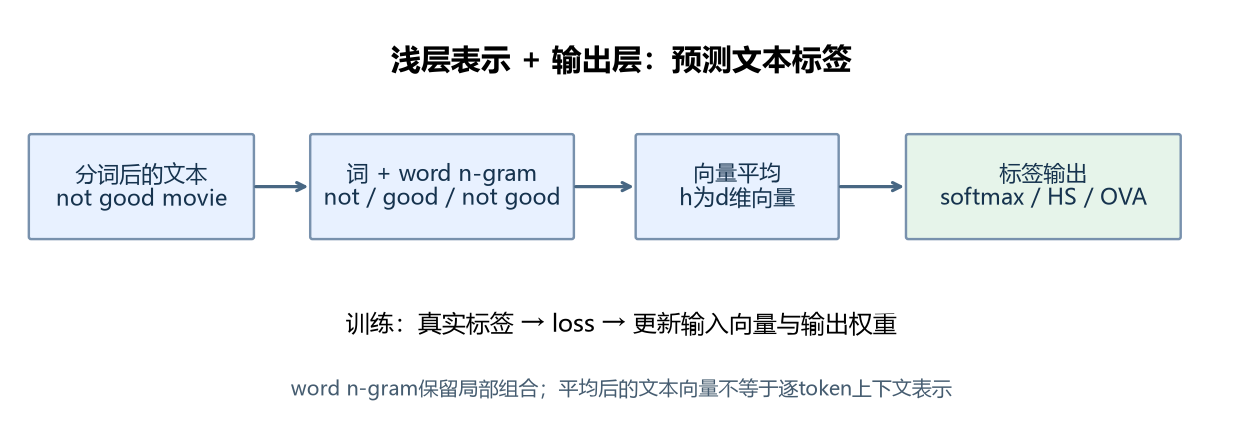

## 4. 哈夫曼树与Hierarchical Softmax（HS）

词或标签很多时，完整softmax输出会涉及所有类别。HS把每个叶节点对应的输出对象放到二叉树上，沿根到目标叶子的路径进行一系列二分类。

哈夫曼树的构造：每次合并当前权重最小的两个节点，重复到只剩根节点。频率高的对象通常获得较短路径，使加权路径长度 `WPL=Σᵢfᵢlᵢ` 最小。它不是保证所有叶子等深的平衡树。

课件例子 `A:5,B:9,C:7,D:3`：先合并D3+A5→8，再合并C7+8→15，最后B9+15→24。路径长度分别为A3、B1、C2、D3，所以 `WPL=5×3+9×1+7×2+3×3=47`。

定义走左分支的概率为 `σ(uᵣᵀh)`，右分支为 `1−σ(uᵣᵀh)`。例如图中D路径为右→右→左：

$$p(D\mid x)=(1-q_{root})(1-q_{15})q_{8}$$

左右编码约定可以交换，关键是每条路径乘对应分支概率。频率用于**构造树**，训练时各节点的分支概率仍依赖当前输入；叶子概率不是固定等于全局频率。

```python
import heapq
freq = {'A':5, 'B':9, 'C':7, 'D':3}
heap = [(f, i, label) for i,(label,f) in enumerate(freq.items())]
heapq.heapify(heap)
serial = len(heap)
while len(heap) > 1:
    f1, _, n1 = heapq.heappop(heap)
    f2, _, n2 = heapq.heappop(heap)
    heapq.heappush(heap, (f1+f2, serial, (n1,n2)))
    serial += 1
codes = {}
def visit(node, code=''):
    if isinstance(node,str):
        codes[node] = code
    else:
        visit(node[0], code+'0')
        visit(node[1], code+'1')
visit(heap[0][2])
wpl = sum(freq[k]*len(codes[k]) for k in freq)
assert wpl == 47
assert all(not codes[a].startswith(codes[b]) for a in codes for b in codes if a!=b)
print('哈夫曼编码:', dict(sorted(codes.items())))
print('WPL:', wpl, '| 前缀编码检查通过')
```

本段实测输出：

```text
哈夫曼编码: {'A': '111', 'B': '0', 'C': '10', 'D': '110'}
WPL: 47 | 前缀编码检查通过
```

HS的训练通常只更新目标路径上的输出节点；路径长度平均约为对数级，但由实际树决定。得到所有类别概率、再取top-k可能还需遍历树，不能把“训练路径短”直接等同于所有预测查询都只做一次O(log C)计算。

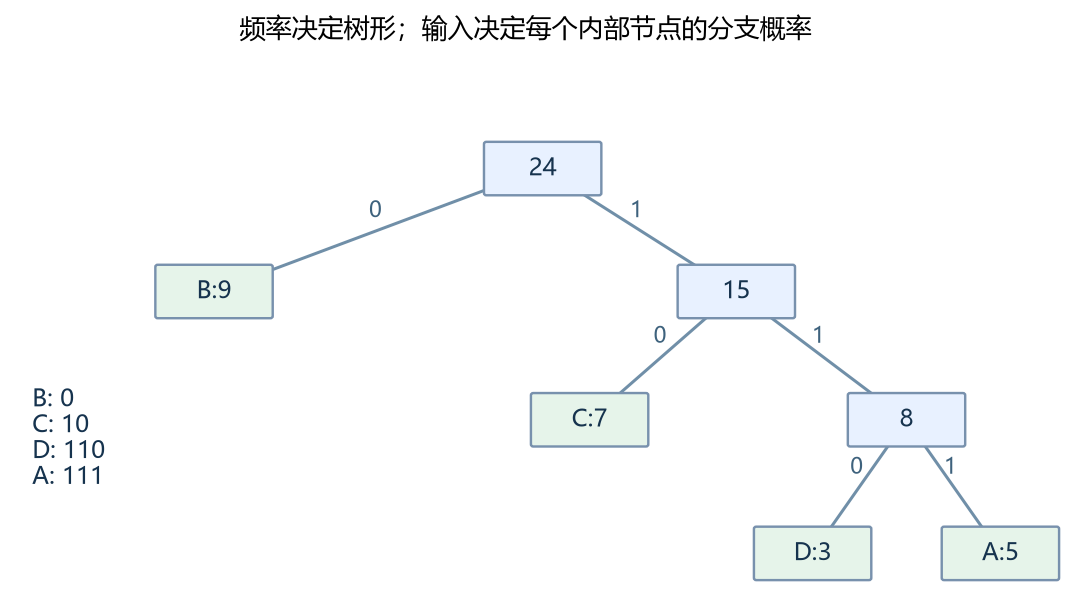

## 5. 负采样：正例 + 少量噪声负例

负采样从噪声分布抽取少量输出对象，训练“真实对象应该打高分，噪声对象应该打低分”。Word2vec常见噪声分布写为 `q(w)∝f(w)^(3/4)`；这个指数不是负采样公式的固定要求，不能未经核对就当作所有FastText实现的采样规定：

$$\mathcal L_{NS}=-\log\sigma(v_{+}^{T}h)-\sum_{k=1}^{K}\log\sigma(-v_{k}^{T}h)$$

采样来自词表上的噪声分布，不是只在当前上下文窗口里找负词。课件“10000输出词、300维、K=5”的例子：一次涉及1个正例+5个负例，即6个输出向量、1800个权重元素；不代表整个模型总共只有1800参数。

```python
def sigmoid(x):
    return 1/(1+np.exp(-np.asarray(x,dtype=float)))
positive_logit, negative_logits = 2.0, np.array([-1.0, .5, -2.0])
ns_loss = -np.log(sigmoid(positive_logit)) - np.log(sigmoid(-negative_logits)).sum()
assert ns_loss > 0 and np.isfinite(ns_loss)
print('正例概率:', round(float(sigmoid(positive_logit)),4))
print('三项负例概率:', np.round(sigmoid(negative_logits),4).tolist())
print('负采样loss:', round(float(ns_loss),4))
```

本段实测输出：

```text
正例概率: 0.8808
三项负例概率: [0.2689, 0.6225, 0.1192]
负采样loss: 1.5412
```

| 方法 | 训练时主要涉及的输出 | 概率含义 | 适用理解 |
| --- | --- | --- | --- |
| softmax | 所有C类 | 完整互斥类别分布 | 监督分类默认loss |
| HS | 目标根到叶路径 | 叶概率由分支连乘 | 大量标签/词的树形输出 |
| NS | 正例和K个负例 | 二分类采样目标；不直接等于完整softmax | 词向量常见训练方式 |
| OVA | 各标签独立二分类 | 每标签独立sigmoid | 多标签分类常用 |

HS和NS是不同训练选择，不是默认同时使用。FastText监督分类默认softmax，而无监督词向量默认常用NS。day10分类调优重点是softmax、hs和ova；不应将负采样理解为自动完成多标签分类的方法。

## 6. 数据格式、预处理与划分

FastText一行是一条样本，标签前缀必须是 `__label__`。多标签可以有多个前缀，标签和文本均以空白分隔：

```text
__label__dessert how to bake a chocolate cake
__label__dessert __label__drink chocolate milk shake recipe
```

课程cooking数据示例有15404条，按12404训练、3000验证处理；本篇不复现该数据成绩。真实数据应先去重、保留来源标识，再做合理划分：可复现打乱适合普通独立样本；时间数据按时间切分，用户/文档来源可按组切分，避免同源内容泄漏。

**本篇人工数据**：cooking、sports、tech三类；60训练、12验证、12测试，使用不同完整句子。每类带明显主题词，任务非常容易。小样本上的高指标只检验接口与流程，不证明业务泛化。验证集用于选择参数；测试集在选完模型后才评估。

```python
def normalize(text):
    text = text.lower()
    text = re.sub(r"([^\w\s])", r" \1 ", text)
    return ' '.join(text.split())

topics = {
    'cooking': ['recipe','kitchen','bake','cake','bread','oven'],
    'sports': ['football','basketball','coach','match','team','score'],
    'tech': ['python','computer','software','code','server','network'],
}
train_templates = [
    'I want to learn about {a} and {b}.', 'How can I improve {a} using {b}?',
    'Today we discuss {a} with {b}.', 'Please explain {a} and {b}!'
]
val_templates = ['Can you help with {a} and {b}?', 'A beginner asks about {a} plus {b}.']
test_templates = ['This lesson covers {a} alongside {b}.', 'I need advice on {a}, especially {b}.']
train_rows, val_rows, test_rows = [], [], []
for label, words in topics.items():
    for i in range(20):
        text = train_templates[i//6].format(a=words[i%6],b=words[(i+1)%6])
        train_rows.append((label,text))
    for i in range(4):
        val_rows.append((label,val_templates[i%2].format(a=words[i],b=words[(i+2)%6])))
        test_rows.append((label,test_templates[i%2].format(a=words[i],b=words[(i+3)%6])))
random.Random(SEED).shuffle(train_rows)
def texts(rows):
    return {normalize(t) for _,t in rows}
assert len(texts(train_rows)) == 60
assert not (texts(train_rows)&texts(val_rows) or texts(train_rows)&texts(test_rows) or texts(val_rows)&texts(test_rows))
def write_ft(path,rows,clean=True):
    path = Path(path)
    lines = []
    for label,text in rows:
        labels = (label,) if isinstance(label,str) else label
        prefix = ' '.join('__label__'+x for x in labels)
        lines.append(prefix+' '+(normalize(text) if clean else text))
    path.write_text('\n'.join(lines)+'\n',encoding='utf-8')
    return str(path)
raw_train = write_ft(WORK/'train_raw.txt',train_rows,False)
raw_val = write_ft(WORK/'val_raw.txt',val_rows,False)
clean_train = write_ft(WORK/'train.txt',train_rows)
clean_val = write_ft(WORK/'val.txt',val_rows)
clean_test = write_ft(WORK/'test.txt',test_rows)
print('train/val/test:',len(train_rows),len(val_rows),len(test_rows))
print('不同划分无重复规范化文本：通过')
print('清洗前:',train_rows[0][1])
print('清洗后:',normalize(train_rows[0][1]))
print('第一行:',Path(clean_train).read_text(encoding='utf-8').splitlines()[0])
```

本段实测输出：

```text
train/val/test: 60 12 12
不同划分无重复规范化文本：通过
清洗前: How can I improve code using server?
清洗后: how can i improve code using server ?
第一行: __label__tech how can i improve code using server ?
```

大小写归一化与标点分离不能机械应用到所有任务，例如实体名、大小写敏感的代码文本可能需要保留。训练与推理必须使用同一个预处理函数。中文需预先分词并用空格连接，FastText不会自动执行jieba；02的分词流程可复用。

## 7. 直接训练、predict与test

下面先运行一个低训练轮数的基线。固定 `dim=32,bucket=5000` 只是为了让小例子轻量；不能把它作为真实业务通用参数。`bucket×dim`会显著影响内存，默认大桶在玩具示例中没有必要。

```python
common = dict(dim=32,bucket=5000,thread=1,seed=SEED,verbose=0)
baseline = fasttext.train_supervised(input=raw_train,epoch=5,lr=.1,wordNgrams=1,loss='softmax',**common)
n0,p0,r0 = baseline.test(raw_val,k=1)
query = 'Please explain python software!'
labels0,probs0 = baseline.predict(query,k=3)
print('原始输入:',query)
print('标签顺序:',labels0)
print('模型分数:',np.round(probs0,4).tolist())
print('基线验证: N={}, P@1={:.3f}, R@1={:.3f}'.format(n0,p0,r0))
assert n0 == len(val_rows)
```

本段实测输出：

```text
原始输入: Please explain python software!
标签顺序: ('__label__tech', '__label__cooking', '__label__sports')
模型分数: [0.3333, 0.3333, 0.3333]
基线验证: N=12, P@1=0.333, R@1=0.333
```

`predict(text,k=1)`返回 `(labels, probabilities)`；`k=3`返回三个候选。传字符串时不要把多条句子直接用换行拼成一条输入；批量预测可以传字符串列表。`test(file,k=1)`返回 `(N,P@1,R@1)`，不是 `(N,accuracy,loss)`。

默认 `threshold=0`；`predict(text,k=-1,threshold=t)`可返回所有达到阈值的候选。k限制最大个数，threshold进一步筛选，数量可能小于k或为0。后面的多标签例子会实际验证这一点。

## 8. P@k、R@k与准确率

记第i条样本真实标签集合为 `Yᵢ`、返回标签集合为 `Ŷᵢ`，FastText的汇总指标按预测标签数和真实标签数计算：

$$P=\frac{\sum_i|Y_i\cap\hat Y_i|}{\sum_i|\hat Y_i|},\qquad R=\frac{\sum_i|Y_i\cap\hat Y_i|}{\sum_i|Y_i|}$$

单标签且每条恰好预测1个标签时，P@1、R@1与top-1 accuracy数值相同。多标签情况下它们与整条样本完全匹配率不同。例如3条样本各有2个真实标签，只返回top-1并且每条都命中：P@1=1，R@1=0.5，却没有一条完整找出所有标签。

```python
true_sets = [{'dessert','drink'},{'drink','cold'},{'dessert','bake'}]
pred_sets = [{'dessert'},{'drink'},{'bake'}]
hits = sum(len(y&p) for y,p in zip(true_sets,pred_sets))
micro_p = hits/sum(map(len,pred_sets))
micro_r = hits/sum(map(len,true_sets))
exact_match = np.mean([y==p for y,p in zip(true_sets,pred_sets)])
print('示意 P@1={:.2f}, R@1={:.2f}, 整条完全匹配率={:.2f}'.format(micro_p,micro_r,exact_match))
assert (micro_p,micro_r,exact_match)==(1.0,.5,0.0)
```

本段实测输出：

```text
示意 P@1=1.00, R@1=0.50, 整条完全匹配率=0.00
```

输出k个标签不等于多标签训练。softmax模型也能返回top-k，它仍假设单标签互斥分布。多标签预测应结合独立输出目标、阈值和标签专属评估，不要用一个“准确率”涵盖所有情况。

## 9. 清洗、epoch、lr、wordNgrams与loss的调优实验

| 参数 | 作用 | 常见误区 |
| --- | --- | --- |
| `epoch` | 遍历训练样本的轮数 | 越多越好；忽视过拟合与计算成本 |
| `lr` | 更新步长 | 从0.1改为1.0一定提升；过大可不稳定 |
| `wordNgrams` | 连续词组最大阶数 | 与minn/maxn混为一谈；阶数越大越好 |
| `loss` | softmax / hs / ova等 | 认为所有任务都适合相同目标 |
| `dim` | 表示维度 | 大维度必然更好，忽略内存 |
| `minCount` | 低频词过滤 | 小语料使用较高阈值导致信息消失 |
| `bucket` | 哈希特征桶数量 | 忽视桶内存、碰撞与词组数量 |

以下四组配置是**组合演示**，同时改变多个因素，不能单凭两组分差推断某个参数的独立贡献。真正的消融实验应保持其他条件相同，一次只改变一个因素，多种随机种子重复比较。

```python
configs = [
    ('原始文本/5轮',raw_train,raw_val,dict(epoch=5,lr=.1,wordNgrams=1,loss='softmax')),
    ('清洗/25轮',clean_train,clean_val,dict(epoch=25,lr=1.0,wordNgrams=1,loss='softmax')),
    ('清洗/二元词组',clean_train,clean_val,dict(epoch=50,lr=.5,wordNgrams=2,loss='softmax')),
    ('清洗/HS',clean_train,clean_val,dict(epoch=50,lr=.5,wordNgrams=2,loss='hs')),
]
results, trained_models = [], []
for name,train_path,val_path,params in configs:
    model = fasttext.train_supervised(input=train_path,**params,**common)
    count,precision,recall = model.test(val_path,k=1)
    results.append(dict(name=name,n=count,p=precision,r=recall))
    trained_models.append(model)
    print('{}: P@1={:.3f}, R@1={:.3f}'.format(name,precision,recall))
# 选择清洗路线中的最佳验证P@1；并列时取先出现的较简单配置。
best_index = max(range(1,len(results)),key=lambda i:results[i]['p'])
best = trained_models[best_index]
print('选中:',results[best_index]['name'])
test_n,test_p,test_r = best.test(clean_test,k=1)
print('选完后测试: N={}, P@1={:.3f}, R@1={:.3f}'.format(test_n,test_p,test_r))
assert test_n == 12
```

本段实测输出：

```text
原始文本/5轮: P@1=0.333, R@1=0.333
清洗/25轮: P@1=1.000, R@1=1.000
清洗/二元词组: P@1=1.000, R@1=1.000
清洗/HS: P@1=1.000, R@1=1.000
选中: 清洗/25轮
选完后测试: N=12, P@1=1.000, R@1=1.000
```

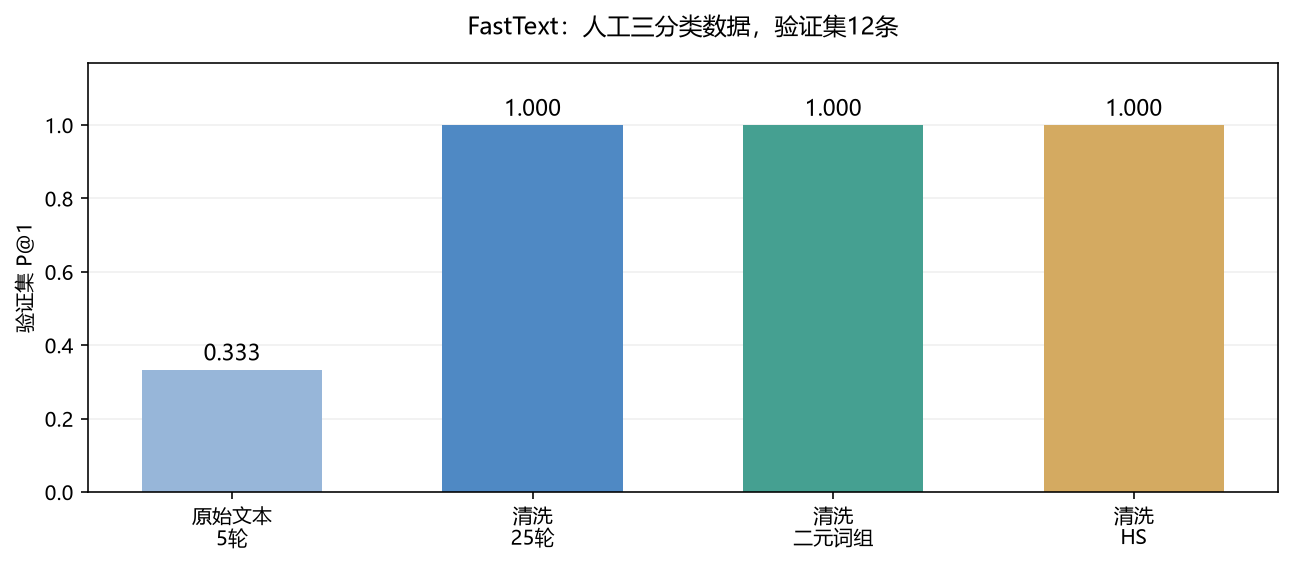

读图时首先看语料规模和划分。本例只有12条验证样本，指标一次变化1/12，无法分辨接近配置的可靠优劣。人工主题词明显，即使出现1.0也不代表生产模型已验收。所有分数来自本篇实际运行，未借用课程cooking数据结果。

## 10. 自动调参：独立验证文件，限定预算

课件使用 `autotuneValidationFile` 和 `autotuneDuration=600`，让FastText在时间预算内尝试配置。结果依赖语料、硬件、版本和可搜索参数，不保证每次完全相同；不是重新划分数据或替你检查泄漏。

**以下为可选示例，未执行**，避免让本篇学习示例自动运行十分钟。实际使用时应提供独立验证集，确认样本数充足；自动搜索完成后，使用一次未参与选型的测试集评估。

```python
auto_model = fasttext.train_supervised(
    input=clean_train,
    autotuneValidationFile=clean_val,
    autotuneDuration=600,
    thread=1,
    verbose=2,
)
print(auto_model.test(clean_test,k=1))
auto_model.save_model(str(WORK/'autotuned.bin'))
```

探索越多配置越容易对验证集过拟合；可以采用更大验证集、交叉验证或另留最终测试集。调参结果应连同预处理、数据版本和评估方式保存，不能只记住某个lr数字。

## 11. 多分类和多标签：softmax与OVA

单标签多分类：一条文本属于多个候选类别中的一个，比如cooking/sports/tech。softmax每类概率在理想数学计算中合计为1。

多标签：一条文本同时属于多个标签，比如“冷巧克力奶昔”同时有 `drink,dessert,cold`。常用 `loss='ova'`（one-vs-all），每个标签单独sigmoid：

$$p_j=\sigma(z_j),\qquad \mathcal L_{OVA}=-\sum_j[y_j\log p_j+(1-y_j)\log(1-p_j)]$$

各标签概率可以同时高或同时低，不要求合计1。统一0.5只是起点，标签不平衡时应在验证集选择阈值；有的场景需要每标签不同阈值。概率分数也未必经过可靠校准。

```python
multi_base = [
    (('dessert','bake'),'cake bread oven bake sweet dessert'),
    (('dessert','bake'),'cookies pastry bake oven dessert'),
    (('drink','cold'),'water ice cold drink refreshing'),
    (('drink','cold'),'juice water cold ice drink'),
    (('dessert','drink','cold'),'milkshake chocolate sweet cold drink dessert'),
    (('drink',),'tea hot drink warm'),
    (('dessert',),'chocolate sweet dessert candy'),
    (('bake',),'bread oven bake dough'),
]
multi_rows = multi_base*20
random.Random(SEED).shuffle(multi_rows)
multi_file = write_ft(WORK/'multi_train.txt',multi_rows)
ova = fasttext.train_supervised(input=multi_file,loss='ova',epoch=50,lr=.2,wordNgrams=2,**common)
multi_query = normalize('milkshake chocolate sweet cold drink dessert')
all_labels,all_scores = ova.predict(multi_query,k=-1,threshold=0)
picked,picked_scores = ova.predict(multi_query,k=-1,threshold=.5)
print('各标签分数:',list(zip(all_labels,np.round(all_scores,4).tolist())))
print('分数合计:',round(float(all_scores.sum()),4))
print('阈值0.5保留:',picked)
assert all(p>=.5 for p in picked_scores)
assert set(picked).issubset(set(all_labels))
assert ova.predict(multi_query,k=-1,threshold=1.0)[0] == ()
print('阈值过高返回空标签：通过')
```

本段实测输出：

```text
各标签分数: [('__label__dessert', 0.9978), ('__label__cold', 0.9975), ('__label__drink', 0.9974), ('__label__bake', 0.0)]
分数合计: 2.9926
阈值0.5保留: ('__label__dessert', '__label__cold', '__label__drink')
阈值过高返回空标签：通过
```

此例重复8种模板用于演示目标函数和阈值，查询也来自训练模板，**不是多标签泛化评估**。真实项目另做验证/测试，报告micro/macro precision、recall、F1、每标签指标与整条匹配率；避免稀有标签被总体平均掩盖。

## 12. 保存、加载与推理一致性

`save_model`保存FastText二进制模型，`fasttext.load_model`重载。文件包含模型参数和字典，但不自动包含自己编写的文本预处理代码、标签中文解释或完整数据处理历史。

```python
model_path = WORK/'topic_classifier.bin'
best.save_model(str(model_path))
loaded = fasttext.load_model(str(model_path))
queries = [normalize('python code server'),normalize('cake bake oven'),normalize('team football match')]
before_labels,before_probs = best.predict(queries,k=3)
after_labels,after_probs = loaded.predict(queries,k=3)
assert before_labels == after_labels
np.testing.assert_allclose(before_probs,after_probs,atol=1e-7,rtol=1e-7)
for text,label,score in zip(queries,after_labels,after_probs):
    print(text,'->',label[0],round(float(score[0]),4))
print('保存/加载标签与分数一致：通过')
print('模型大小(KiB):',round(model_path.stat().st_size/1024,1))
```

本段实测输出：

```text
python code server -> __label__tech 1.0
cake bake oven -> __label__cooking 1.0
team football match -> __label__sports 1.0
保存/加载标签与分数一致：通过
模型大小(KiB): 5.9
```

至少同时保存：模型、预处理策略、标签映射、关键参数、库版本、训练数据标识和验证/测试结果。加载文件名成功并不等于语料处理一致；分类接口应统一调用 `normalize`，并明确中文分词方式、空文本与长文本的处理策略。

## 13. 词向量迁移：加载使用、特征迁移与再训练

课件介绍Common Crawl + Wikipedia等预训练FastText词向量，中文例子为 `cc.zh.300.bin.gz`。课件记录的语言数量属于当时发布信息，不应作为所有当前模型永久不变的规格；以实际模型说明为准。

| 操作 | 是否更新参数 | 准确称呼 |
| --- | --- | --- |
| 加载已有模型，调用get_word_vector | 否 | 直接使用预训练表示/推理 |
| 使用固定向量训练自己的分类器 | 向量固定、分类器更新 | 特征迁移 |
| 使用预训练向量初始化，再在任务数据上更新 | 是 | 参数迁移/任务微调 |
| 在新的无标签领域语料继续预训练 | 是 | 领域适配/继续预训练 |

**加载模型后打印向量不是微调。** FastText `.bin`包含模型与子词等信息，通常能基于子词为未登录词生成向量；`.vec`是导出的词表及静态向量，单独文件不含完整子词模型，不能同样恢复所有OOV能力。

下面训练一个很小的无监督模型，只检验向量API、维度及OOV路径；小语料的近邻不作为语义质量证据。

```python
unsup_file = WORK/'unlabeled.txt'
unsup_file.write_text('\n'.join(normalize(t) for _,t in train_rows)+'\n',encoding='utf-8')
vectors_demo = fasttext.train_unsupervised(input=str(unsup_file),model='skipgram',
    dim=16,minCount=1,minn=3,maxn=5,bucket=2000,epoch=10,thread=1,verbose=0)
known_vec = vectors_demo.get_word_vector('python')
oov_token = 'pythonista'
oov_vec = vectors_demo.get_word_vector(oov_token)
assert vectors_demo.get_word_id(oov_token) == -1
assert known_vec.shape == oov_vec.shape == (16,)
assert np.isfinite(oov_vec).all()
print('已知词/OOV向量shape:',known_vec.shape,oov_vec.shape)
print('OOV是否在词表:',vectors_demo.get_word_id(oov_token))
print('OOV向量范数:',round(float(np.linalg.norm(oov_vec)),6))
vectors_demo.save_model(str(WORK/'vectors_demo.bin'))
print('向量API与有限数值检查：通过；未验收语义近邻')
```

本段实测输出：

```text
已知词/OOV向量shape: (16,) (16,)
OOV是否在词表: -1
OOV向量范数: 0.009194
向量API与有限数值检查：通过；未验收语义近邻
```

OOV向量由子词构造，不等于模型理解新词；如果相关子词未学好，结果也可能差。监督分类的embedding学的是当前标签任务，也不能自动当作通用语义表示。本篇FastText0.9.2的 `train_unsupervised` Python入口不接受 `seed` 参数，此处使用库默认随机设置和单线程；复现重点是shape、OOV检查和有限数值，不要求范数小数末位相同。

### 13.1 使用真实预训练向量的可选流程（未执行）

从 [FastText官方预训练向量](https://fasttext.cc/docs/en/crawl-vectors.html) 选择匹配语言的模型，并核对许可、大小和版本。`.gz`需先解压为`.bin`。以下不自动下载数GB文件。

```python
pretrained_path = Path('cc.zh.300.bin')
assert pretrained_path.exists(), '请先准备解压后的中文预训练模型'
zh_vectors = fasttext.load_model(str(pretrained_path))
vector = zh_vectors.get_word_vector('音乐')
print(vector.shape)
print(zh_vectors.get_nearest_neighbors('音乐',k=5))
```

若使用预训练`.vec`初始化监督分类，接口是 `pretrainedVectors`，且 `dim`应与文件维度一致；不是将`.bin`直接传给此参数。词形和分词也必须对应。

```python
# 使用与当前训练文本语言一致的静态向量文件；示例未执行。
transferred = fasttext.train_supervised(
    input=clean_train,
    pretrainedVectors='cc.en.300.vec',
    dim=300,
    epoch=10,
    wordNgrams=2,
)
```

这个训练调用使用预训练输入向量作初始化，并会在有标签任务上更新；新任务的标签输出层仍要学习。是否改善效果，需要与随机初始化基线在同样数据划分上比较。

## 14. 迁移学习：复用哪些知识，训练哪些参数

源任务/源语料已有的参数或表示，被用于新的目标任务或领域，这就是迁移学习。NLP常见路线是大量无标签语料上的自监督预训练，再在较少的任务标签上微调；预训练不要求一定是超大参数模型，也不等于“全部由人工标签监督”。

三种实际选择：①直接使用已训练好的目标任务模型进行推理；②冻结编码器，用它抽取特征，训练新的任务头；③加载预训练编码器，添加目标头，更新头和部分/全部编码器参数。领域继续预训练与任务微调也可以串联。

**新增分类头只是增加一个结构。** 如果分类头随机初始化、没有标签训练，它给出的类别和高分不能代表真实情感识别。微调至少包括匹配标签的数据、loss、反向传播、优化步骤，以及独立验证。

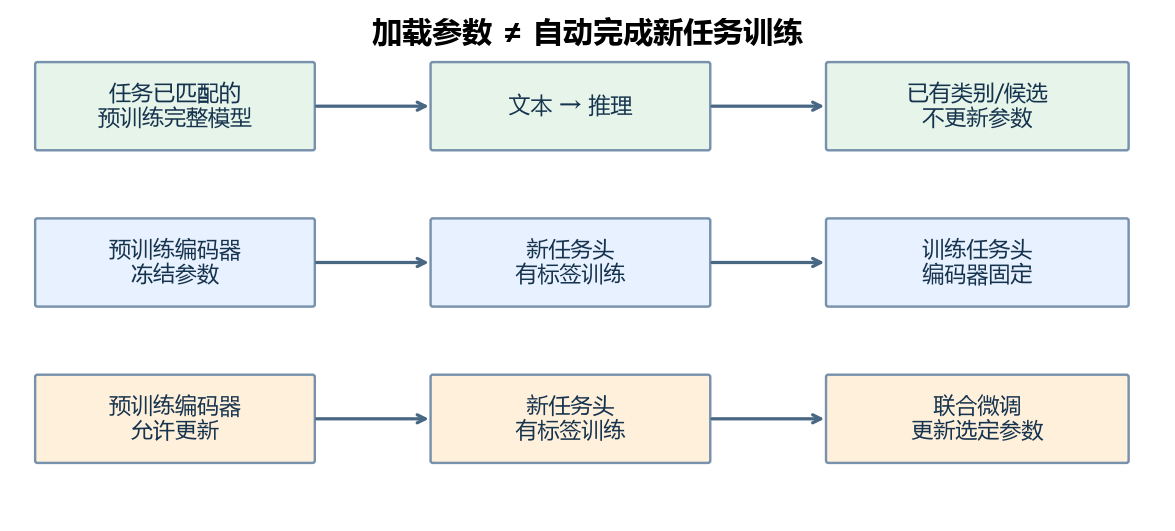

微调时注意tokenizer、特殊token、label2id/id2label、模型架构与任务一致；参数更多不自动更适合小数据。冻结编码器可减少训练成本，但不能直接解决领域差异与标签定义差异。

## 15. 常见预训练架构与目标

| 架构/家族 | 主要信息访问方式 | 常见预训练目标 | 常见任务 |
| --- | --- | --- | --- |
| Decoder-only，如GPT/GPT-2 | causal attention，看已知前缀 | 预测下一个token | 续写、对话、条件生成 |
| Encoder-only，如BERT | 双向读取输入上下文 | Masked Language Modeling（BERT另有NSP） | 理解、分类、token表示、填空 |
| RoBERTa | 双向编码 | 改进BERT训练方式，一般无NSP | 理解、分类 |
| ALBERT | 双向编码、参数共享与嵌入分解 | MLM、句序等目标 | 更节省参数的编码 |
| ELECTRA | 双向编码器 | 替换token检测（RTD） | 理解与下游任务 |
| Encoder-Decoder，如T5/BART | 编码完整输入、解码条件生成 | 文本去噪/片段恢复等 | 翻译、摘要、文本到文本任务 |
| XLNet | permutation语言建模 | 排列自回归目标 | 不应简单等同于固定左到右GPT |

课件的“AR/AE/混合”分类可以帮助入门，但**架构、预训练目标和下游任务是三个不同维度**。BERT的MLM、ELECTRA的RTD不相同；完整Transformer含encoder与decoder，也不意味着任何同名模型都是完整双栈结构。

不要背课件历史模型表中的所有参数量：例如GPT/GPT-2应归为decoder-only；ALBERT的参数共享与嵌入分解意味着其参数量不能直接照抄普通BERT；`cased`区分大小写，`uncased`通常执行大小写归一化。模型隐藏维度、层数、最大长度、语言与标签应以具体config、tokenizer和model card为准。

本篇本地BERT `hidden_size=32`，不会得到768维；课件 `bert-base-chinese` 的768维属于那个具体模型配置。

## 16. Transformers三种调用层次与Pipeline流程

| 层次 | 典型接口 | 开发者主要负责什么 |
| --- | --- | --- |
| Pipeline | `pipeline(task=...,model=...,tokenizer=...)` | 选择适合任务的模型、输入、推理参数 |
| Auto系列 | `AutoTokenizer`, `AutoModelForSequenceClassification`等 | 自己组织输入、训练、后处理 |
| 具体模型类 | `BertModel`, `BertForMaskedLM`等 | 明确架构，精细控制模型与任务头 |

Auto不是只支持BERT家族，也不是自动帮你训练。Pipeline通常封装 **预处理 → 模型前向 → 后处理**，默认用于推理；它不会自动完成新标签任务的微调。

```text
原始文本
   ↓ tokenizer：input_ids / attention_mask /（部分模型的token_type_ids）
模型前向：编码器 + 可选任务头
   ↓ 后处理：softmax / sigmoid / 取mask位置 / 标签映射等
Python列表、字典、分数或特征张量
```

Pipeline可以使用Hub模型ID，也可以加载本地已保存的模型目录或直接接收模型对象。生产与复现实验建议明确model、tokenizer和固定revision，不依赖随版本变化的默认模型。模型目录需要模型权重、config及完整tokenizer资源，不能只放一个词表或任意权重文件。

| 任务 | 常见匹配类 | 输出 |
| --- | --- | --- |
| `text-classification` / `sentiment-analysis` | `...ForSequenceClassification` | label、score |
| `feature-extraction` | 无任务头的基础编码器 | token级hidden states |
| `fill-mask` | `...ForMaskedLM` | token、token_str、sequence、score |

任务字符串不会把基础BERT自动变成训练好的情感模型。加载基础checkpoint到分类类时，新头可能被随机初始化；应读清加载提示并按任务训练。

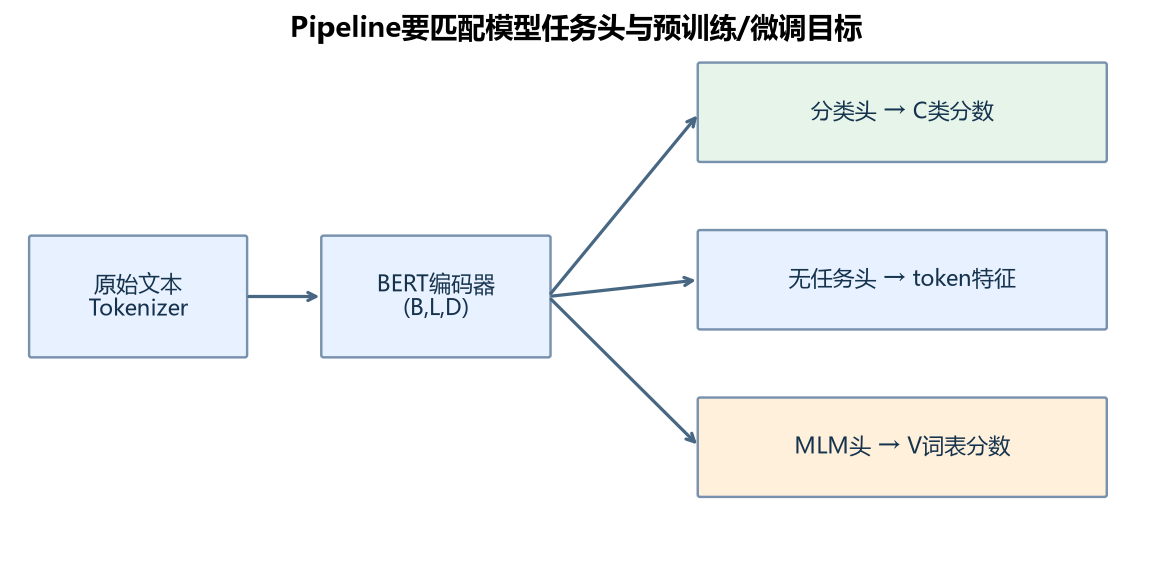

## 17. 本地小BERT：离线验证三种接口

为了不依赖联网下载，本篇创建一个中文单字词表和随机初始化小BERT：1层、4头、hidden_size=32，随机分类头含2类。本节没有预训练或微调，后面的类别/填空候选只是计算结果，**不解释为真实情感或正确答案**。

```python
from transformers import (
    pipeline,BertConfig,BertTokenizerFast,
    BertModel,BertForSequenceClassification,BertForMaskedLM,
)
chars = list(dict.fromkeys('我你他爱喜欢讨厌这电影好坏很精彩无聊天气晴朗今天明天去家吃饭。'))
vocab = ['[PAD]','[UNK]','[CLS]','[SEP]','[MASK]']+chars
vocab_path = WORK/'vocab.txt'
vocab_path.write_text('\n'.join(vocab)+'\n',encoding='utf-8')
tokenizer = BertTokenizerFast(vocab_file=str(vocab_path),do_lower_case=False,model_max_length=64)
small_config = BertConfig(
    vocab_size=len(tokenizer),hidden_size=32,num_hidden_layers=1,
    num_attention_heads=4,intermediate_size=64,max_position_embeddings=64,
    pad_token_id=tokenizer.pad_token_id,
    num_labels=2,id2label={0:'NEGATIVE',1:'POSITIVE'},
    label2id={'NEGATIVE':0,'POSITIVE':1},
)
classification_model = BertForSequenceClassification(small_config)
feature_model = BertModel(small_config)
masked_model = BertForMaskedLM(small_config)
# 共享相同编码器初值进行任务头对照，不共享参数对象；仍是随机权重。
classification_model.bert.load_state_dict(feature_model.state_dict())
masked_model.bert.load_state_dict(feature_model.state_dict(),strict=False)
for model in (classification_model,feature_model,masked_model):
    model.eval()
text_demo = '这电影很精彩。'
encoded = tokenizer(text_demo,return_tensors='pt')
print('词表大小:',len(tokenizer),'| D:',small_config.hidden_size)
print('分词:',tokenizer.convert_ids_to_tokens(encoded['input_ids'][0]))
print('input_ids shape:',tuple(encoded['input_ids'].shape))
print('attention_mask:',encoded['attention_mask'].tolist())
assert tokenizer.unk_token_id not in encoded['input_ids'][0].tolist()
```

本段实测输出：

```text
词表大小: 34 | D: 32
分词: ['[CLS]', '这', '电', '影', '很', '精', '彩', '。', '[SEP]']
input_ids shape: (1, 9)
attention_mask: [[1, 1, 1, 1, 1, 1, 1, 1, 1]]
```

真实中文BERT常把汉字拆开，但还会处理英文、数字、WordPiece等，不是“任何字符串长度都等于字数+2”。这里的单字词表是教学简化；正式应用必须使用目标checkpoint配套的tokenizer。

## 18. 文本分类Pipeline：标签含义由训练定义

`sentiment-analysis`是文本分类的常见别名。模型被训练成星级评分、主题类别或情感二分类，决定返回什么标签；一个 `LABEL_0` 或 `star 5` 不能脱离模型说明自行翻译成“负面/正面”。下面的标签名由本篇config明确设置，但权重随机，所以只是接口验证。

```python
classifier = pipeline('text-classification',model=classification_model,tokenizer=tokenizer,device=-1)
class_inputs = ['这电影很精彩。','这电影很无聊。']
class_output = classifier(class_inputs,top_k=None,truncation=True,max_length=32)
print('随机模型分类输出:',class_output)
for row in class_output:
    assert {p['label'] for p in row}=={'NEGATIVE','POSITIVE'}
    assert abs(sum(p['score'] for p in row)-1)<1e-6
print('两条输入、每条2类、softmax合计1：通过')
```

本段实测输出：

```text
随机模型分类输出: [[{'label': 'NEGATIVE', 'score': 0.5015145540237427}, {'label': 'POSITIVE', 'score': 0.4984854459762573}], [{'label': 'NEGATIVE', 'score': 0.5015183687210083}, {'label': 'POSITIVE', 'score': 0.4984816610813141}]]
两条输入、每条2类、softmax合计1：通过
```

`top_k=None`返回所有类别，输出嵌套结构与单条/多条输入、调用参数有关，不要盲目固定取 `output[0]['label']`。`device=-1`指定CPU；有可用GPU时可选择对应设备，先确认环境。

多标签Transformer需要匹配训练方式、`problem_type='multi_label_classification'`以及独立sigmoid输出；不是单纯把top_k扩大。FastText的ova参数不能直接套用到Transformers。

## 19. 特征提取Pipeline：输出token表示，不自动得到句向量

特征提取不接分类或MLM头，一般得到 `(B,L,D)`。课件“人生该如何起头”有7个汉字，加入 `[CLS]` 和 `[SEP]` 后L=9，`bert-base-chinese`的D=768。本篇文本和模型不同，shape以实际tokenizer与config为准。

```python
extractor = pipeline('feature-extraction',model=feature_model,tokenizer=tokenizer,device=-1)
features = np.asarray(extractor(text_demo,tokenize_kwargs={'truncation':True,'max_length':32}),dtype=np.float32)
with torch.no_grad():
    direct_hidden = feature_model(**encoded).last_hidden_state.numpy()
np.testing.assert_allclose(features,direct_hidden,atol=1e-6,rtol=1e-6)
print('Pipeline shape:',features.shape)
print('直接模型最大差:',round(float(np.max(np.abs(features-direct_hidden))),8))

# 如需句向量，可显式池化，排除PAD和特殊token。
batch = tokenizer([text_demo,'天气很好。'],padding=True,
    return_special_tokens_mask=True,return_tensors='pt')
special_mask = batch.pop('special_tokens_mask')
with torch.no_grad():
    hidden = feature_model(**batch).last_hidden_state
valid = batch['attention_mask'].bool() & ~special_mask.bool()
weights = valid.unsqueeze(-1).to(hidden.dtype)
sentence_vectors = (hidden*weights).sum(dim=1)/weights.sum(dim=1).clamp_min(1)
assert sentence_vectors.shape==(2,32) and torch.isfinite(sentence_vectors).all()
print('batch token特征shape:',tuple(hidden.shape))
print('有效token数:',valid.sum(dim=1).tolist())
print('显式均值池化shape:',tuple(sentence_vectors.shape))
long_features = np.asarray(extractor(text_demo*10,
    tokenize_kwargs={'truncation':True,'max_length':32}),dtype=np.float32)
assert long_features.shape==(1,32,32)
print('长文本截断后的shape:',long_features.shape)
```

本段实测输出：

```text
Pipeline shape: (1, 9, 32)
直接模型最大差: 0.0
batch token特征shape: (2, 9, 32)
有效token数: [7, 5]
显式均值池化shape: (2, 32)
长文本截断后的shape: (1, 32, 32)
```

`[CLS]`位置向量、排除PAD后的均值、专门训练的句向量模型是不同方案。普通BERT输出做均值池化不保证句子相似度效果；随机小模型的向量更无语义依据。特征Pipeline默认可返回大量嵌套列表，长文本和大量数据时应考虑内存、截断、分批与张量输出。

中文句子长度、实际token数、模型最大输入长度也不相同。`truncation=True`可能丢掉尾部信息，必须根据任务确认，不能静默截断关键内容后仍把结果当成全文理解。本篇实测版本的特征提取Pipeline通过 `tokenize_kwargs` 传递 `max_length`，不能假设所有Pipeline都把任意同名参数自动传给tokenizer；上面的长文本检查确认实际长度被限制为32。

## 20. fill-mask：取mask位置，再对词表预测

输入中的mask是 `tokenizer.mask_token`；BERT通常为 `[MASK]`，RoBERTa常见为 `<mask>`。不能给所有模型硬编码相同字符串。

MLM头把 `(B,L,D)`映射为 `(B,L,V)`；Pipeline取出mask位置的V维分数，softmax后选top-k。一个mask填的是一个token，可能是单字或子词，不自动等于一个完整中文词、任意长度短语或开放式续写。

```python
filler = pipeline('fill-mask',model=masked_model,tokenizer=tokenizer,device=-1)
masked_text = '这电影很'+tokenizer.mask_token+'。'
mask_output = filler(masked_text,top_k=3)
mask_input = tokenizer(masked_text,return_tensors='pt')
mask_positions = (mask_input['input_ids'][0]==tokenizer.mask_token_id).nonzero().flatten()
assert len(mask_positions)==1
with torch.no_grad():
    mask_logits = masked_model(**mask_input).logits
    mask_probs = mask_logits[0,int(mask_positions[0])].softmax(-1)
print('随机模型填空候选:',mask_output)
print('MLM logits shape:',tuple(mask_logits.shape))
for candidate in mask_output:
    assert abs(candidate['score']-float(mask_probs[candidate['token']]))<1e-6
topk_sum = sum(c['score'] for c in mask_output)
print('top-3概率合计:',round(topk_sum,4),'（不要求为1）')
print('Pipeline候选分数与直接MLM概率一致：通过')
```

本段实测输出：

```text
随机模型填空候选: [{'score': 0.03643687441945076, 'token': 29, 'token_str': '去', 'sequence': '这 电 影 很 去 。'}, {'score': 0.0338473841547966, 'token': 5, 'token_str': '我', 'sequence': '这 电 影 很 我 。'}, {'score': 0.032719165086746216, 'token': 10, 'token_str': '欢', 'sequence': '这 电 影 很 欢 。'}]
MLM logits shape: (1, 8, 34)
top-3概率合计: 0.103 （不要求为1）
Pipeline候选分数与直接MLM概率一致：通过
```

输出字段：`token`是词表ID，`token_str`是对应token文本，`sequence`是替换后解码文本，`score`是该候选概率。top-k只取部分词表，合计通常小于1；decode可能有空格和WordPiece标记处理，不是原字符串的逐字符无损替换。

本篇固定使用单mask，便于解释。多mask在不同版本可有不同支持和结果结构，也不等于联合最优解。BERT fill-mask也不等于GPT式从左到右续写。

## 21. 本地模型目录保存与Pipeline重载

Transformers与FastText的保存接口不同：前者常用 `save_pretrained` 保存目录，后者使用 `save_model` 保存`.bin`。本篇额外保存一个小MLM目录，验证tokenizer、config和权重可以离线一起恢复。

```python
local_mlm_dir = WORK/'tiny_random_mlm'
masked_model.save_pretrained(local_mlm_dir)
tokenizer.save_pretrained(local_mlm_dir)
reloaded_mlm = BertForMaskedLM.from_pretrained(local_mlm_dir,local_files_only=True)
reloaded_tokenizer = BertTokenizerFast.from_pretrained(local_mlm_dir,local_files_only=True)
local_filler = pipeline('fill-mask',model=reloaded_mlm,tokenizer=reloaded_tokenizer,device=-1)
reloaded_output = local_filler(masked_text,top_k=3)
assert [x['token'] for x in reloaded_output]==[x['token'] for x in mask_output]
np.testing.assert_allclose([x['score'] for x in reloaded_output],
    [x['score'] for x in mask_output],atol=1e-7,rtol=1e-7)
print('本地目录:',local_mlm_dir)
print('文件:',sorted(p.name for p in local_mlm_dir.iterdir()))
print('保存/重载候选ID及分数一致：通过')
```

本段实测输出：

```text
本地目录: nlp_day10_demo\tiny_random_mlm
文件: ['config.json', 'model.safetensors', 'special_tokens_map.json', 'tokenizer.json', 'tokenizer_config.json', 'vocab.txt']
保存/重载候选ID及分数一致：通过
```

随机小模型保存后仍然是随机小模型；“本地加载成功”不能替代“已预训练/微调”的事实。正式模型应记录下载来源、revision与许可，并保留匹配的tokenizer资源。

## 22. 中文预训练Pipeline的实际使用模板（未执行）

以下模型ID是公开模型使用示例，不是本篇实测输出。第一次运行会联网下载权重并缓存，耗时和磁盘占用由checkpoint决定；下载后的本地目录也可以替换Hub ID使用。

```python
from transformers import pipeline

# 情感分类：选择已经过中文情感任务微调的模型。
sentiment_id = 'uer/roberta-base-finetuned-jd-binary-chinese'
sentiment = pipeline('text-classification',model=sentiment_id,tokenizer=sentiment_id,device=-1)
print(sentiment('这件商品质量不错。',truncation=True))

# 基础编码器：抽取token特征，不把它当作已训练好的情感分类头。
base_id = 'google-bert/bert-base-chinese'
real_features = pipeline('feature-extraction',model=base_id,tokenizer=base_id,device=-1)
print(np.asarray(real_features('人生该如何起头')).shape)

# 配套MLM头：预测单个mask位置的词表token。
mlm_id = 'hfl/chinese-bert-wwm'
real_filler = pipeline('fill-mask',model=mlm_id,tokenizer=mlm_id,device=-1)
print(real_filler('我想明天去'+real_filler.tokenizer.mask_token+'家吃饭。',top_k=5))
```

在模型页面查看 `id2label`、训练数据与适用范围：京东商品评论模型不能直接证明适合新闻、医疗或其他领域；标签ID也需要结合模型说明解释。WWM指预训练中按词整体mask的策略，不意味着推理时一个 `[MASK]` 能输出任意长度整词。

为复现正式结果，应使用经核对的固定commit作为 `revision` 并同步用于模型/tokenizer；不要在笔记中编造revision。加载时不要忽略“某些任务头新初始化”的提示；下载失败时可准备正确的完整本地目录，排查网络和缓存，不应关闭证书验证来绕过问题。

## 23. 课件勘误与常见错误

| 位置/问题 | 容易形成的错误理解 | 本篇采用的理解 |
| --- | --- | --- |
| 上篇第14页题3 | “树形结构”选C | 按该页选项应选D，与课件答案C不一致 |
| 上篇第15页负采样题 | 负样本仅从上下文窗口挑选 | 从输出词表的噪声分布采样 |
| 上篇FastText分类评估 | test的两个指标叫准确率 | 返回precision、recall；仅特定单标签top-1时等值 |
| 上篇词向量迁移 | load_model + get_word_vector叫再训练 | 未发生更新，是加载推理；微调需实际训练 |
| 中篇第13—17页历史模型表 | GPT用encoder；cased不分大小写；参数量全部可背诵 | GPT为decoder-only；cased区分大小写；规格核对config/model card |
| 中篇文本分类示例/总结 | 普通bert-base-chinese天然具备情感头 | 基础预训练模型不自动有训练好的情感分类头 |
| 中篇第32页特征例子 | 768维和“汉字数+2”适合所有模型 | D由config决定；L由实际tokenizer决定 |
| 中篇第33页fill-mask | 一个mask自动生成一整句话 | 预测被遮蔽位置的一个token；不是开放式生成 |
| 预测概率 | top-k总和必须1，OVA总和必须1 | softmax全类合计1；top-k可小于1；OVA互相独立 |
| 预处理与划分 | 更换清洗方式后沿用旧模型；调测试集阈值 | 训练推理一致；只用验证集选参数和阈值 |

这些更正针对已阅读的PDF，不推断课程视频或原代码是否另有修正。示例模型、数据、输出均明确区分课件与本篇独立实验。

## 24. 复习题与参考答案

1. **FastText分类与CBOW的共同点和区别？** 都可平均输入特征，前者监督目标是标签，后者预测词；结构相似不代表任务相同。
2. **wordNgrams=2是否等于中文字符2-gram？** 否，它是相邻输入词/空白token的二元组合；字符子词由minn/maxn控制。
3. **哈夫曼树为什么让高频对象路径短？** 最小化按频率加权的路径长度，降低平均训练成本。
4. **HS与负采样能说默认同时启用吗？** 不能，是不同输出训练选择；监督分类默认softmax。
5. **多标签3条样本各2标签，top-1全部命中，P/R是多少？** P@1=1，R@1=0.5，整条完全匹配率可能是0。
6. **返回top-3就成为多标签模型吗？** 否；输出个数与训练目标不同，多标签常需OVA/独立sigmoid。
7. **为什么验证集和测试集不能混用？** 验证负责选型，测试估计最终未参与选择的数据表现。
8. **加载预训练FastText向量为什么不叫微调？** 没有loss、反向传播和参数更新；只是复用表示。
9. **加一个随机分类头后就能情感分析吗？** 只能计算分数，头还需任务数据训练与验证。
10. **Pipeline会自动训练模型吗？** 不会；它主要封装预处理、前向与后处理。
11. **B=2、L=9、D=32、V=40时，特征与MLM logits分别是什么shape？** `(2,9,32)`和`(2,9,40)`；分类头通常输出`(2,C)`。
12. **中文BERT的mask总是一个完整词吗？** 不一定，一个mask对应一个token，取决于tokenizer；WWM不改变该推理事实。
13. **普通BERT的均值池化能直接当优秀句向量吗？** 可以作为简单特征方案尝试，但必须评估；不保证相似度质量。
14. **本篇随机Pipeline输出能用于真实判别吗？** 不能，它只验证接口、shape与数值一致性。

练习：用真实分词后的中文主题数据替换人工英文语料，保持无泄漏划分；先建立FastText基线，再一次只修改一个参数。另用适合该领域的已微调Transformer做对照，同时记录效果、延迟、资源开销和错误案例，不能只比较一条输入的最高分。

## 25. day10资料索引与实测范围

来源：[NLP自然语言处理网盘资料](https://pan.baidu.com/s/16JhWSR5VZu0tEQ0EcRJBwA?pwd=1234)，提取码 `1234`。课程目录 `2026最新版NLP自然语言处理`，视频 `03-视频/day10`，共17个文件。

阅读课件：`09-迁移学习-上.pdf` 第1—44页；`10-迁移学习-中.pdf` 第1—39页，第40—41页仅核对下一部分边界。中篇第35—37页还有问答、摘要、NER的简介，本篇按day10视频列表只详细整理前三个Pipeline任务。

| 视频 | 原文件主题 | 对应笔记 |
| --- | --- | --- |
| 01 | Fasttext_简介及环境搭建(理解) | 第1—3节 |
| 02 | Fasttext_哈夫曼树介绍(理解) | 第4节 |
| 03 | Fasttext_负采样介绍(理解) | 第5节 |
| 04 | Fasttext_直接训练_代码实现(掌握) | 第6—8节 |
| 05 | Fasttext优化_数据预处理(掌握) | 第6、9节 |
| 06 | Fasttext优化_调整训练轮数和学习率(掌握) | 第9节 |
| 07 | Fasttext优化_调整NGram和损失函数(掌握) | 第3、9节 |
| 08 | Fasttext优化_自动调参(掌握) | 第10节 |
| 09 | Fasttext优化_多分类多标签任务(掌握) | 第8、11节 |
| 10 | Fasttext_模型保存和加载(掌握) | 第12节 |
| 11 | Fasttext_词向量迁移介绍(理解) | 第13节 |
| 12 | 迁移学习介绍(理解) | 第14节 |
| 13 | 常见的预训练NLP模型介绍(理解) | 第15节 |
| 14 | Transformers库介绍及环境搭建(理解) | 第2、16—17节 |
| 15 | NLP任务_Pipeline方式_文本分类(掌握) | 第18、22节 |
| 16 | NLP任务_Pipeline方式_特征提取(掌握) | 第19、22节 |
| 17 | NLP任务_Pipeline方式_完形填空(掌握) | 第20—22节 |

本篇执行了：哈夫曼树/WPL、负采样公式数值、数据文件写入与跨划分重复检查、FastText单标签训练/预测/P/R、四组配置验证与最终测试、OVA阈值与空预测、FastText保存重载、小语料子词OOV向量、三种本地随机BERT Pipeline、token/MLM分数与直接前向对照、特殊token/PAD排除池化，以及本地Transformer目录保存重载。

未执行：600秒自动调参、数GB预训练FastText向量下载、预训练`.vec`初始化监督分类、公开中文情感/BERT/WWM checkpoint推理。可选代码不附实测输出。人工主题数据与多标签训练模板不替代真实业务评估，随机BERT不提供预训练语义能力。

五张图均为本篇独立绘制并内嵌：FastText流程、哈夫曼树、实际配置结果、迁移路线、Pipeline任务头。

补充查阅：[FastText监督分类教程](https://fasttext.cc/docs/en/supervised-tutorial.html)、[FastText选项说明](https://fasttext.cc/docs/en/options.html)、[Transformers Pipeline文档](https://huggingface.co/docs/transformers/main_classes/pipelines)。本篇接口实测版本固定记录，不将动态网页文档当作历史课件逐字内容。